In [251]:
import sys
import os
base_dir = r"C:\Users\acostamendoza\projects\distance-project"
data_dir = r"D:\data-distance-coding-project\processed-data"
sys.path.append(base_dir)
from src.RadialExperiment import RadialDevice, RadialPlots, RadialSummaries
import numpy as np
import matplotlib.pyplot as plt
import pickle

%load_ext autoreload
%autoreload 2

mouse_name = 'SAM040'
record_date = '251130'
experiment_name = 'tiling_9_120um'

data_dir = os.path.join(data_dir, f'{record_date}_{mouse_name}_{experiment_name}')
summ_name = f'{record_date}_{mouse_name}_{experiment_name}_summaries.pkl'
summ_dir = os.path.join(data_dir, summ_name)

try:
    with open(summ_dir, 'rb') as f:
        summ = pickle.load(f)
        print(f"File {summ_dir} imported.")
except FileNotFoundError:
    print(f"The file {summ_dir} does not exist.")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
The file D:\data-distance-coding-project\processed-data\251130_SAM040_tiling_9_120um\251130_SAM040_tiling_9_120um_summaries.pkl does not exist.


In [252]:
# Initialize RadialDevice (matches notebook usage)
print("\nInitializing RadialDevice...")
D = RadialDevice(
    mouse_name=mouse_name, 
    record_date=record_date, 
    experiment_name=experiment_name
)

print(f"Loaded {len(D.suite2p_id)} cells")
print(f"Data directory: {D.data_dir}")

# Run session analysis (matches notebook: D.analyze_session_stats())
print("\nRunning session statistics analysis...")
stats_df = D.analyze_session_stats(n_iterations=100)

# Save statistics
results_dir = os.path.join(D.data_dir, 'results')
os.makedirs(results_dir, exist_ok=True)
stats_file = os.path.join(results_dir, 'session_stats.csv')
stats_df.to_csv(stats_file, index=False)
print(f"Statistics saved to: {stats_file}")

# Initialize plots
plots = RadialPlots(D)

# Initialize summaries (matches notebook usage)
print("\nInitializing RadialSummaries...")
summ = RadialSummaries(radial_class=D, radial_stats=stats_df, radial_plots=plots)

print(f"Found {len(summ.responsive_cells)} responsive cells")
print(f"Found {sum(len(cells) for cells in summ.modulated_cells.values())} total modulated cells")

# Save summ object as pickle
summ_file = os.path.join(D.data_dir, f'{record_date}_{mouse_name}_{experiment_name}_summaries.pkl')
import pickle
with open(summ_file, 'wb') as f:
    pickle.dump(summ, f)
print(f"RadialSummaries object saved to: {summ_file}")


Initializing RadialDevice...
[ok] Loading session: 251130_SAM040_tiling_9_120um
Creating directory: results
Successfully loaded activity data
Stimulus file found
Repeat stimulus on length distribution:
    98 repeats have length 61
    22 repeats have length 62
Set stimulus on length: 61
Loaded 1606 cells
Data directory: D:/data-distance-coding-project/processed-data\251130_SAM040_tiling_9_120um

Running session statistics analysis...
Total cells: 160655 of 3355
Responsive cells: 93 (5.8%)
Statistics saved to: D:/data-distance-coding-project/processed-data\251130_SAM040_tiling_9_120um\results\session_stats.csv

Initializing RadialSummaries...
Total cells: 1606
Responsive cells: 125 (7.8%)
Monocular modulated cells: 1 (0.8%)
Binocular modulated cells: 8 (6.4%)
Both modulated cells: 0 (0.0%)
Non-modulated cells: 116 (92.8%)
Found 125 responsive cells
Found 125 total modulated cells
RadialSummaries object saved to: D:/data-distance-coding-project/processed-data\251130_SAM040_tiling_9_120

C:\Users\acostamendoza\projects\distance-project\src\RadialExperiment.py:1296: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
C:\Users\acostamendoza\projects\distance-project\src\RadialExperiment.py:1296: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
C:\Users\acostamendoza\projects\distance-project\src\RadialExperiment.py:1296: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
C:\Users\acostamendoza\projects\distance-project\src\RadialExperiment.py:1351: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
C:\Users\acostamendoza\projects\distance-project\src\RadialExperiment.py:1353: UserWarning: This f

Summary maps saved to: D:/data-distance-coding-project/processed-data\251130_SAM040_tiling_9_120um\results\responsive_map.png, D:/data-distance-coding-project/processed-data\251130_SAM040_tiling_9_120um\results\binocular_map.png, D:/data-distance-coding-project/processed-data\251130_SAM040_tiling_9_120um\results\monocular_map.png, D:/data-distance-coding-project/processed-data\251130_SAM040_tiling_9_120um\results\distance_bars.png, D:/data-distance-coding-project/processed-data\251130_SAM040_tiling_9_120um\results\distance_polar.png


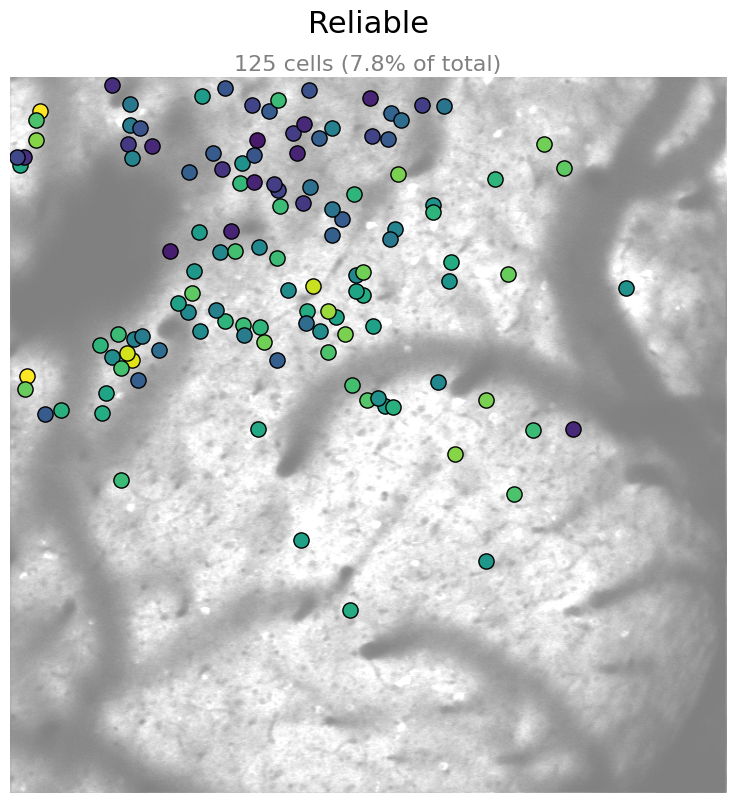

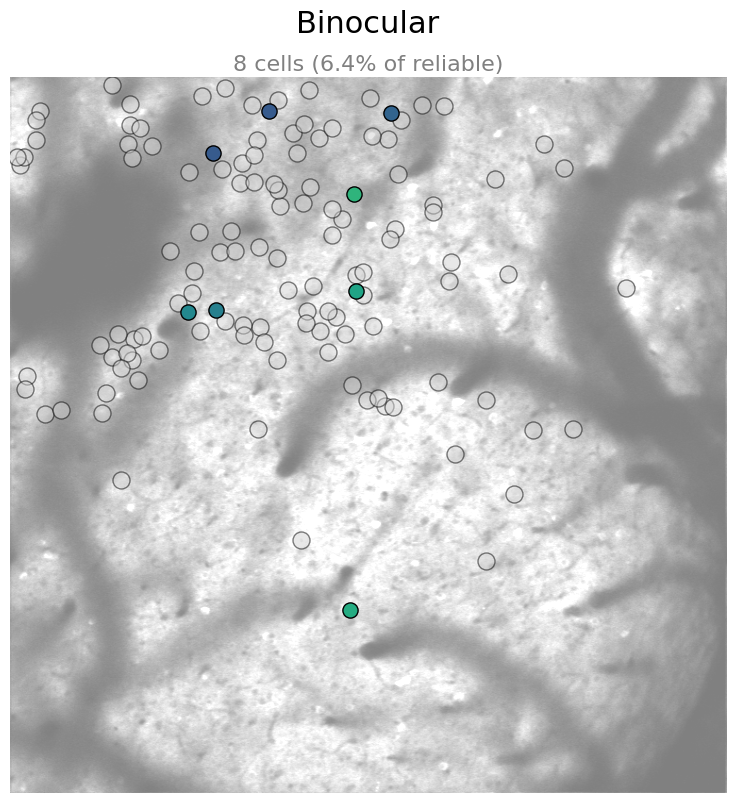

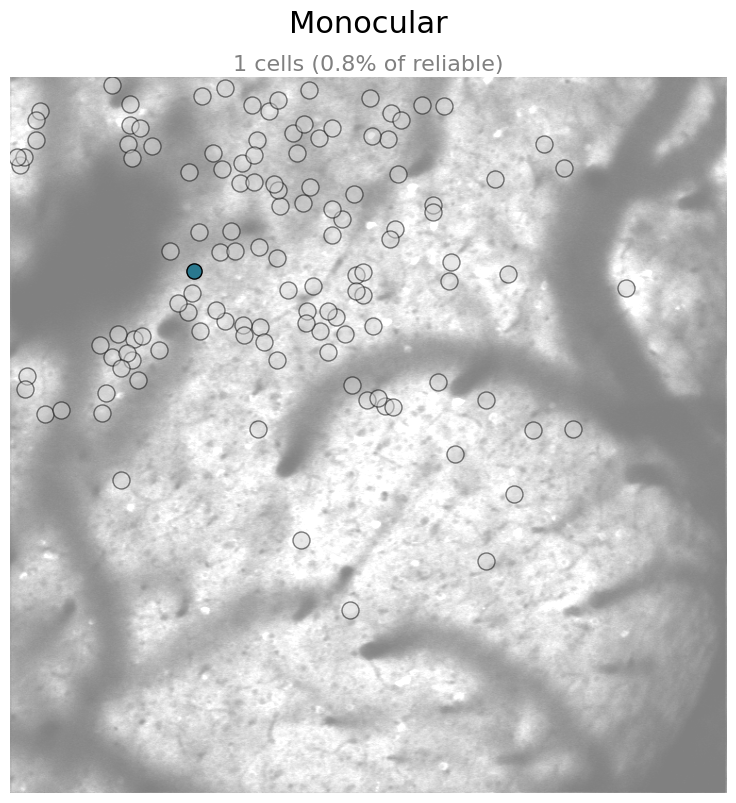

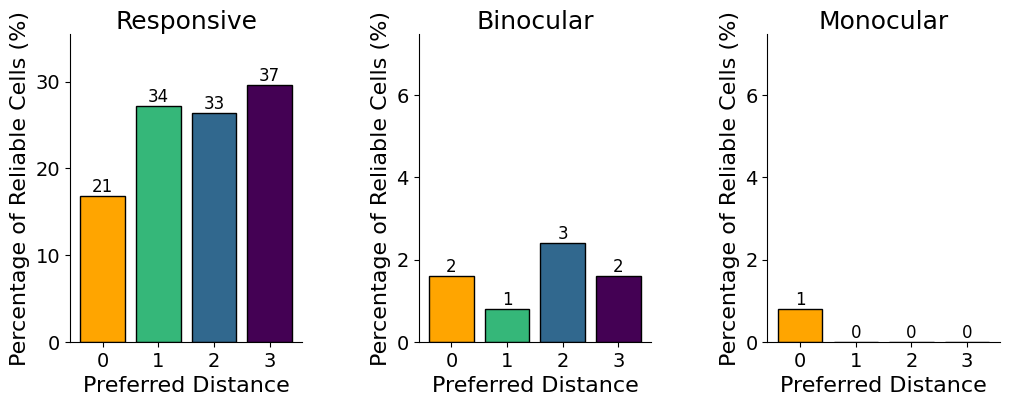

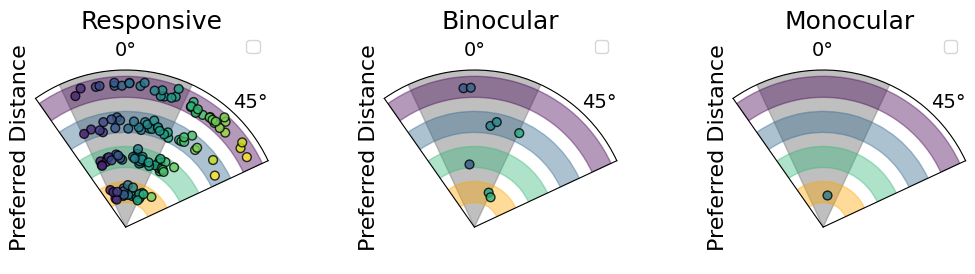

In [253]:
fig_responsive_map, fig_binocular_map, fig_monocular_map, fig_distance_bars, fig_distance_polar = summ.plot_session_summary()
responsive_map_file = os.path.join(results_dir, 'responsive_map.png')
binocular_map_file = os.path.join(results_dir, 'binocular_map.png')
monocular_map_file = os.path.join(results_dir, 'monocular_map.png')
distance_bars_file = os.path.join(results_dir, 'distance_bars.png')
distance_polar_file = os.path.join(results_dir, 'distance_polar.png')
fig_responsive_map.savefig(responsive_map_file, dpi=300, bbox_inches='tight')
fig_binocular_map.savefig(binocular_map_file, dpi=300, bbox_inches='tight')
fig_monocular_map.savefig(monocular_map_file, dpi=300, bbox_inches='tight')
fig_distance_bars.savefig(distance_bars_file, dpi=300, bbox_inches='tight')
fig_distance_polar.savefig(distance_polar_file, dpi=300, bbox_inches='tight')
print(f"Summary maps saved to: {responsive_map_file}, {binocular_map_file}, {monocular_map_file}, {distance_bars_file}, {distance_polar_file}")

In [229]:
summ.plot_single_cells()

Plotting monocular cells
Creating directory: monocular
Plotting binocular cells
Creating directory: binocular
Plotting both cells
Creating directory: both
Plotting none cells
Creating directory: none


In [215]:
spikes = D.spikes[:, :-1]
# # save spikes as spks in suite2p folder
np.save(os.path.join(D.suite2p_dir, 'spks.npy'), spikes)

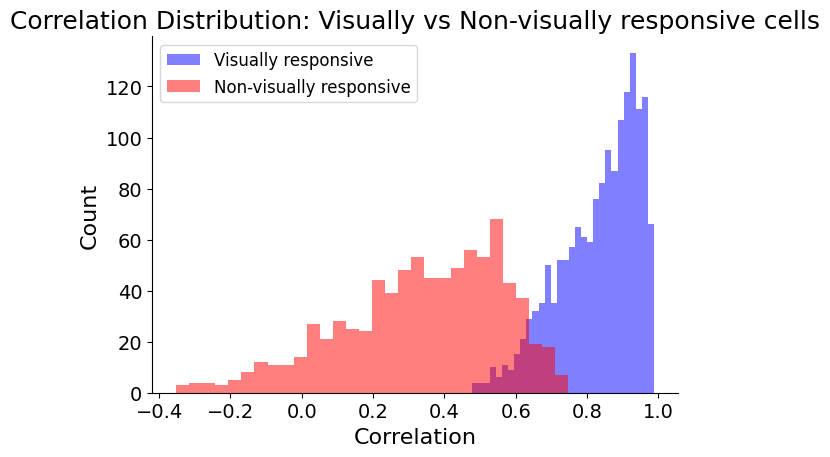

In [ ]:
visually_responsive_corr = summ.radial_stats[summ.radial_stats['responsive_visually'] == True]['responsive_corr'].values
non_visually_responsive_corr = summ.radial_stats[summ.radial_stats['responsive_visually'] == False]['responsive_corr'].values

plt.figure()
plt.hist(visually_responsive_corr, bins=30, alpha=0.5, label='Visually responsive', color='blue')
plt.hist(non_visually_responsive_corr, bins=30, alpha=0.5, label='Non-visually responsive', color='red')
plt.xlabel('Correlation')
plt.ylabel('Count')
plt.title('Correlation Distribution: Visually vs Non-visually responsive cells')
plt.legend()
plt.tight_layout()

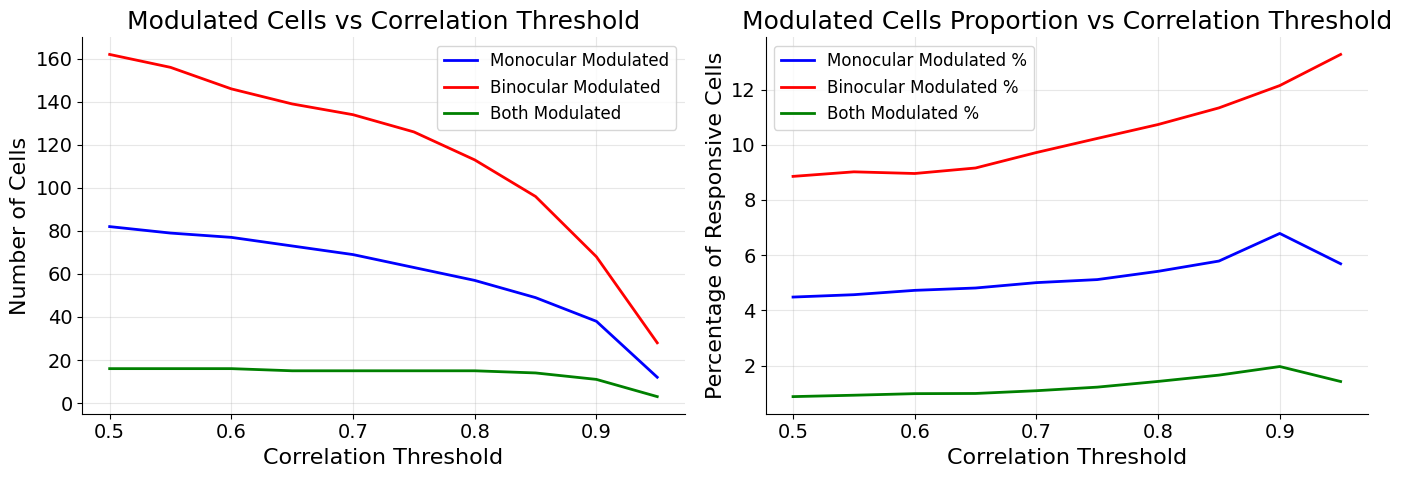


At correlation threshold = 0.80:
Total responsive cells: 1053
Monocular modulated: 57 (5.4%)
Binocular modulated: 113 (10.7%)
Both modulated: 15 (1.4%)


In [25]:
# Analyze modulated cells across different correlation thresholds
thresholds = np.arange(0.5, 1.0, 0.05)
monocular_modulated_counts = []
binocular_modulated_counts = []
both_modulated_counts = []
total_responsive_counts = []

for threshold in thresholds:
    # Count responsive cells at this threshold
    responsive = summ.radial_stats[summ.radial_stats['responsive_corr'] >= threshold]
    total_responsive_counts.append(len(responsive))
    
    # Count modulated cells among responsive cells
    monocular_mod = len(responsive[responsive['monocular_modulated'] == True])
    binocular_mod = len(responsive[responsive['binocular_modulated'] == True])
    both_mod = len(responsive[(responsive['monocular_modulated'] == True) & (responsive['binocular_modulated'] == True)])
    
    monocular_modulated_counts.append(monocular_mod)
    binocular_modulated_counts.append(binocular_mod)
    both_modulated_counts.append(both_mod)

# Plot the results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: Absolute counts
# ax1.plot(thresholds, total_responsive_counts, 'k-', linewidth=2, label='Total Responsive')
ax1.plot(thresholds, monocular_modulated_counts, 'b-', linewidth=2, label='Monocular Modulated')
ax1.plot(thresholds, binocular_modulated_counts, 'r-', linewidth=2, label='Binocular Modulated')
ax1.plot(thresholds, both_modulated_counts, 'g-', linewidth=2, label='Both Modulated')
ax1.set_xlabel('Correlation Threshold')
ax1.set_ylabel('Number of Cells')
ax1.set_title('Modulated Cells vs Correlation Threshold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Right plot: Proportions
ax2.plot(thresholds, np.array(monocular_modulated_counts) / np.array(total_responsive_counts) * 100, 
         'b-', linewidth=2, label='Monocular Modulated %')
ax2.plot(thresholds, np.array(binocular_modulated_counts) / np.array(total_responsive_counts) * 100, 
         'r-', linewidth=2, label='Binocular Modulated %')
ax2.plot(thresholds, np.array(both_modulated_counts) / np.array(total_responsive_counts) * 100, 
         'g-', linewidth=2, label='Both Modulated %')
ax2.set_xlabel('Correlation Threshold')
ax2.set_ylabel('Percentage of Responsive Cells')
ax2.set_title('Modulated Cells Proportion vs Correlation Threshold')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary at current threshold (0.85)
current_threshold = 0.8
idx = np.argmin(np.abs(thresholds - current_threshold))
print(f"\nAt correlation threshold = {thresholds[idx]:.2f}:")
print(f"Total responsive cells: {total_responsive_counts[idx]}")
print(f"Monocular modulated: {monocular_modulated_counts[idx]} ({monocular_modulated_counts[idx]/total_responsive_counts[idx]*100:.1f}%)")
print(f"Binocular modulated: {binocular_modulated_counts[idx]} ({binocular_modulated_counts[idx]/total_responsive_counts[idx]*100:.1f}%)")
print(f"Both modulated: {both_modulated_counts[idx]} ({both_modulated_counts[idx]/total_responsive_counts[idx]*100:.1f}%)")


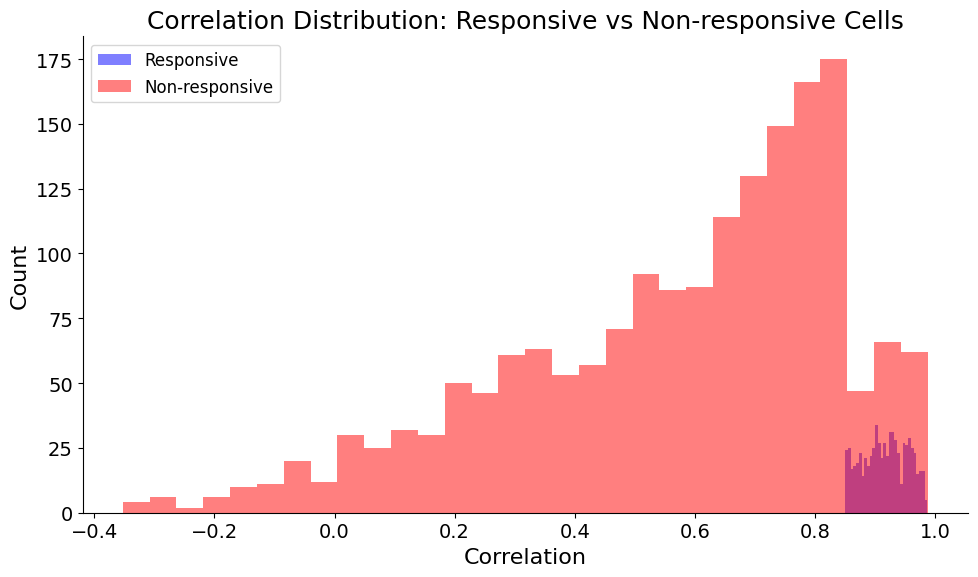

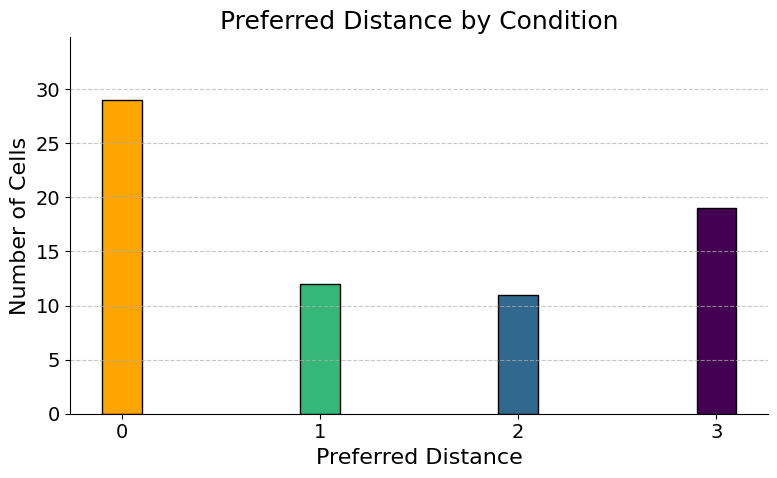

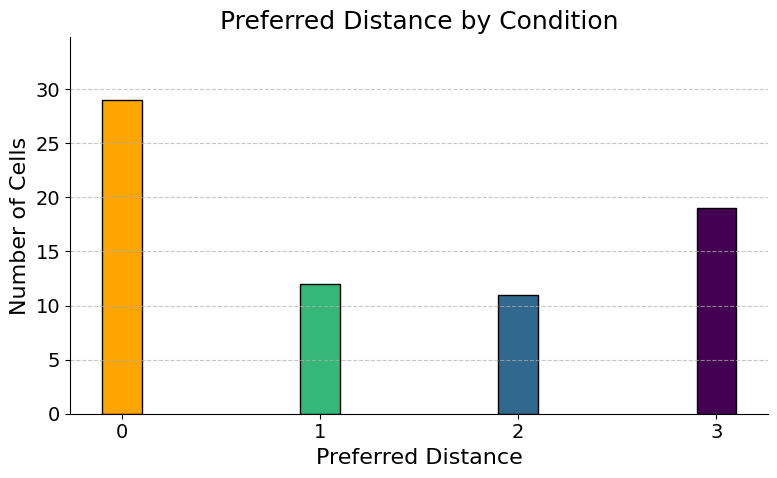

In [115]:
summ.plot_preferred_distance_bars(condition='binocular')

C:\Users\acostamendoza\projects\distance-project\src\RadialExperiment.py:1296: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  else:
C:\Users\acostamendoza\projects\distance-project\src\RadialExperiment.py:1296: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  else:
C:\Users\acostamendoza\projects\distance-project\src\RadialExperiment.py:1296: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  else:
C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_49136\3599853407.py:29: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


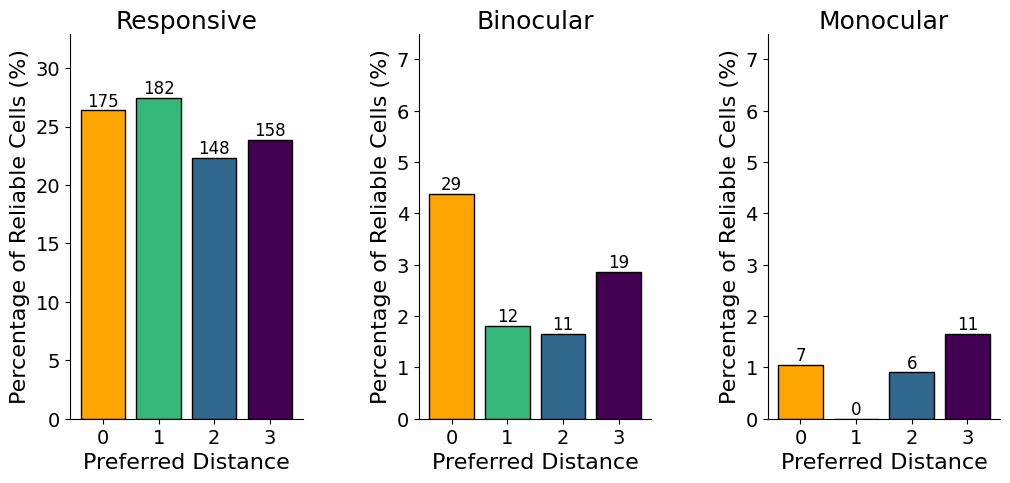

In [ ]:
# fig = plt.figure(figsize=(12, 18))
# gs = fig.add_gridspec(1, 3, hspace=0.3, wspace=0.5)

# # Create polar plots in first row
# axes_polar = []
# for i in range(3):
#     ax = fig.add_subplot(gs[0, i], projection='polar')
#     axes_polar.append(ax)
fig
# summ.plot_preferred_distance_polar(condition=None, ax=axes_polar[0])
# summ.plot_preferred_distance_polar(condition='binocular', ax=axes_polar[1])
# summ.plot_preferred_distance_polar(condition='monocular', ax=axes_polar[2])


fig = plt.figure(figsize=(12, 5))
gs = fig.add_gridspec(1, 3, hspace=0.3, wspace=0.5)

# Create bar plot axes in second row
axes_bar = []
for i in range(3):
    ax = fig.add_subplot(gs[0, i])
    axes_bar.append(ax)

# Call each plotting function with the appropriate axis
summ.plot_preferred_distance_bars(condition=None, ax=axes_bar[0])
summ.plot_preferred_distance_bars(condition='binocular', ax=axes_bar[1])
summ.plot_preferred_distance_bars(condition='monocular', ax=axes_bar[2])

plt.tight_layout()

(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': '71 cells (10.7% of reliable)'}>)

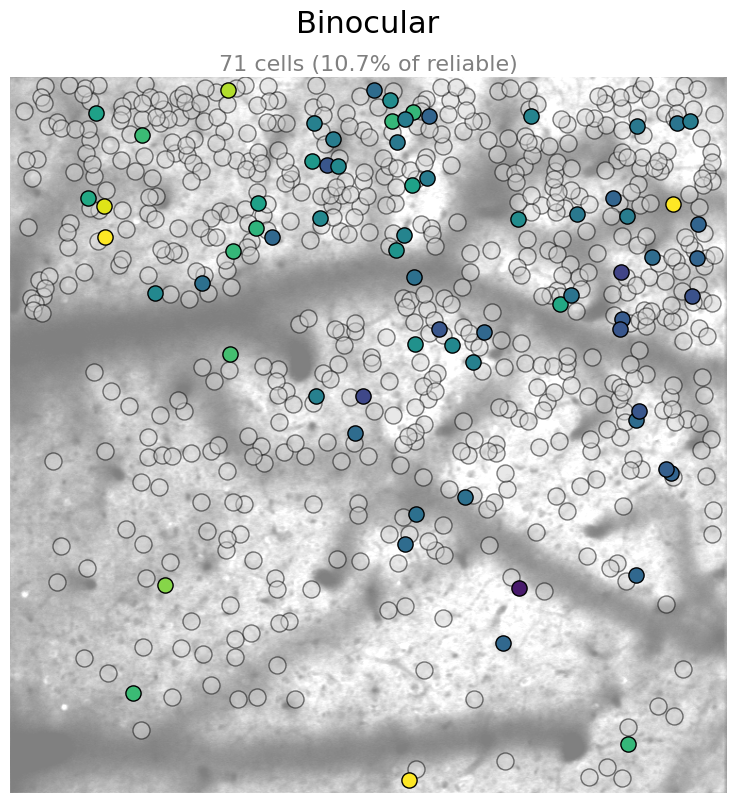

In [195]:
summ.plot_modulated_cells_map(condition='binocular')

C:\Users\acostamendoza\projects\distance-project\src\RadialExperiment.py:1296: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
C:\Users\acostamendoza\projects\distance-project\src\RadialExperiment.py:1296: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
C:\Users\acostamendoza\projects\distance-project\src\RadialExperiment.py:1296: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
C:\Users\acostamendoza\projects\distance-project\src\RadialExperiment.py:1351: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
C:\Users\acostamendoza\projects\distance-project\src\RadialExperiment.py:1353: UserWarning: This f

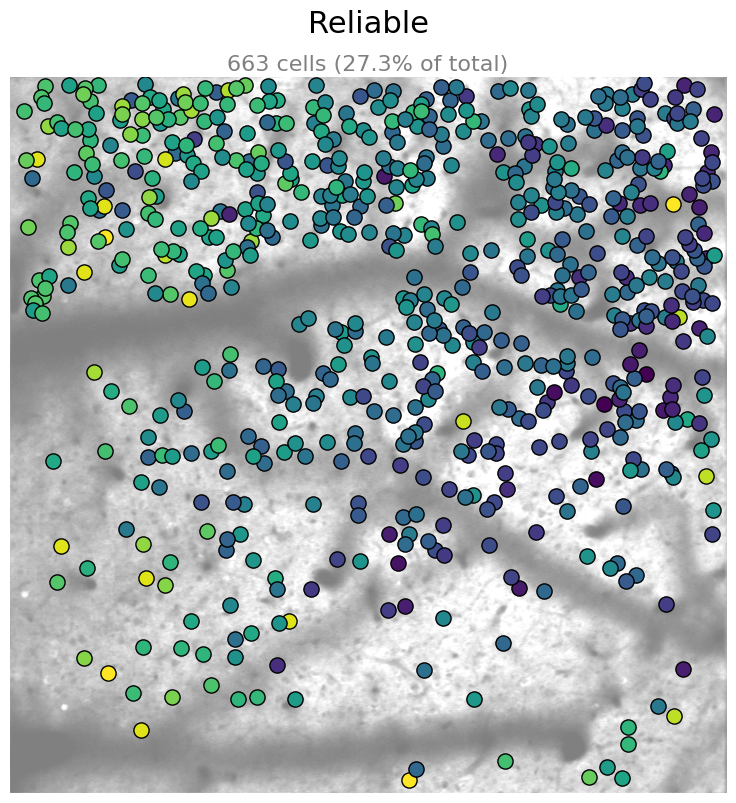

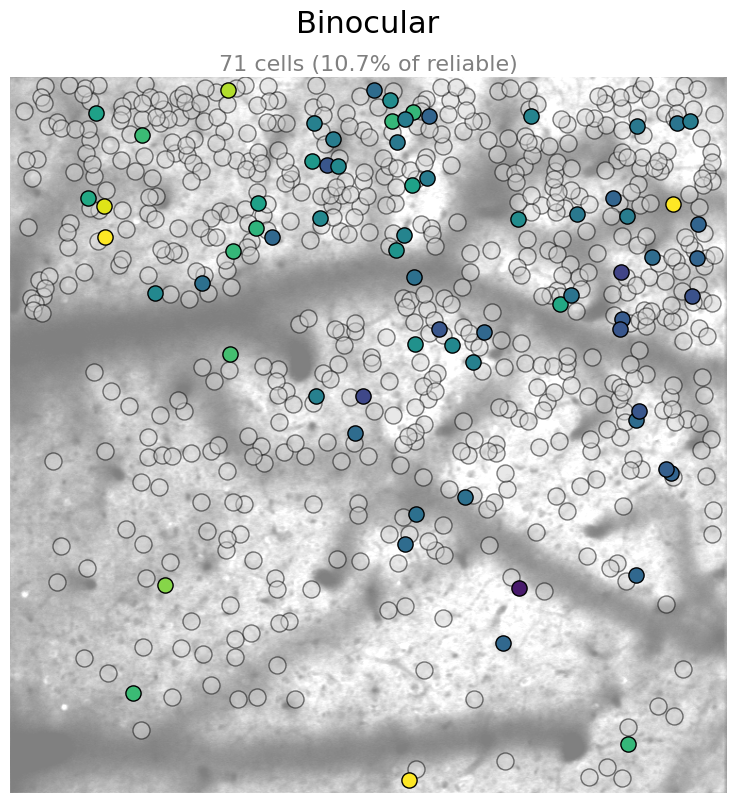

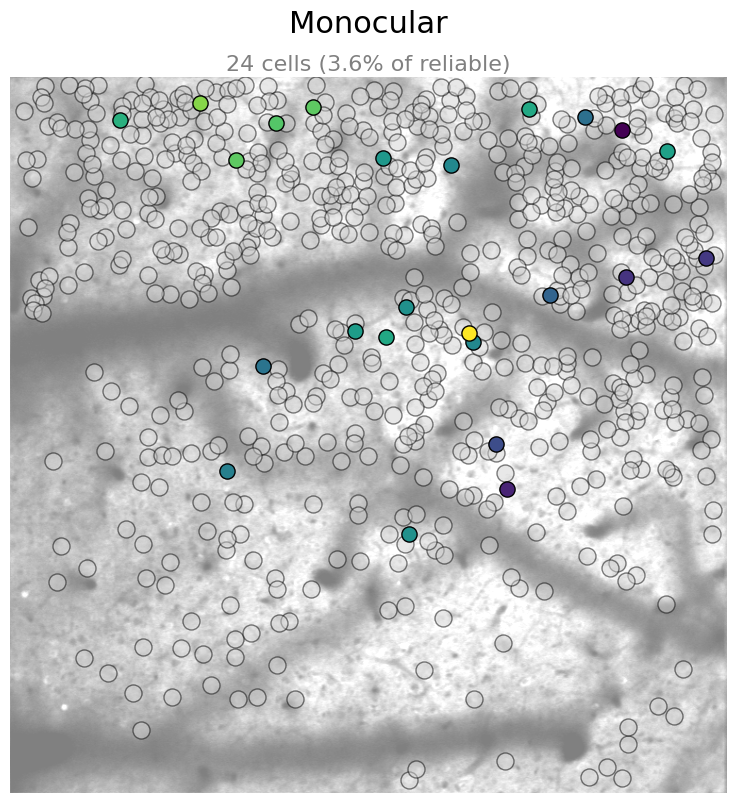

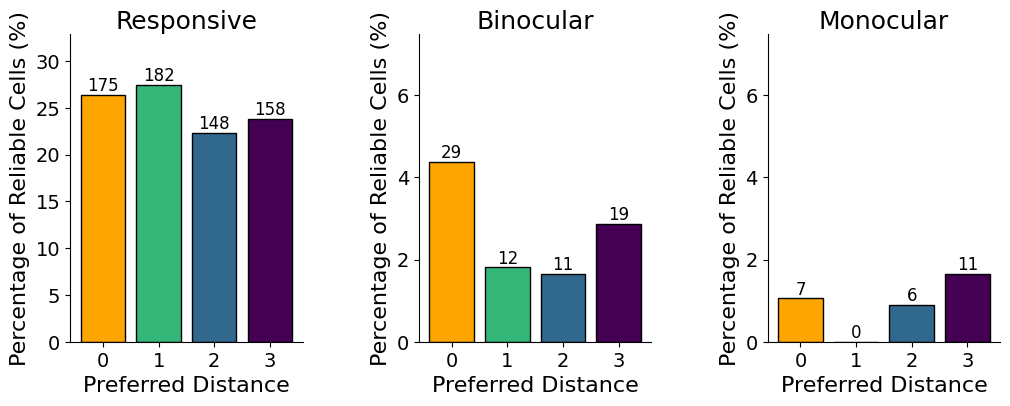

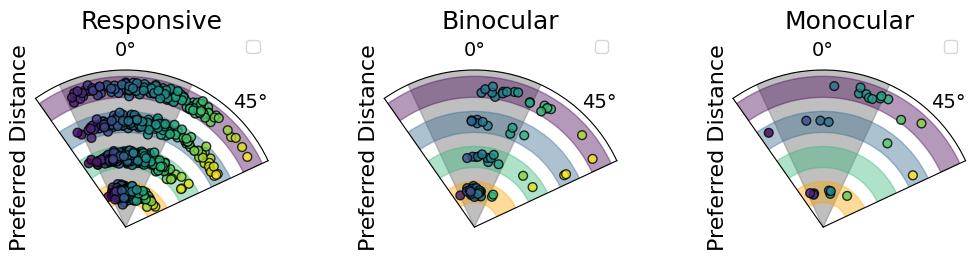

In [198]:
fig_responsive_map, fig_binocular_map, fig_monocular_map, fig_distance_bars, fig_distance_polar = summ.plot_session_summary()

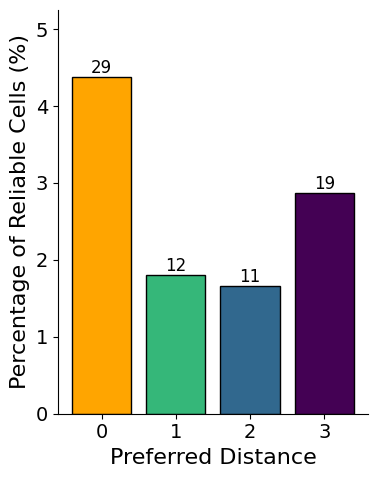

In [130]:
fig, ax = plt.subplots(figsize=(4, 5))

condition = 'binocular'

modulated_cells = summ.modulated_cells[condition]

if condition is None:
    all_pref_distances = summ.radial_stats[summ.radial_stats['cell_id'].isin(modulated_cells)]['distance'].values
else:
    all_pref_distances = summ.radial_stats[summ.radial_stats['cell_id'].isin(modulated_cells)][condition + '_distance'].values

distances = [0, 1, 2, 3]
counts = [sum(all_pref_distances == d) for d in distances]

# Calculate percentage of reliable cells
total_reliable = len(summ.responsive_cells)
percentages = [(count / total_reliable) * 100 for count in counts]

ax.bar(distances, percentages, width=0.8, color=summ.colors, edgecolor='black')

# Add raw counts on top of bars
for i, (distance, percentage, count) in enumerate(zip(distances, percentages, counts)):
    ax.text(distance, percentage, str(count), ha='center', va='bottom', fontsize=12)

ax.set_ylabel('Percentage of Reliable Cells (%)')
ax.set_xlabel('Preferred Distance')
ax.set_xticks(distances)
ax.set_xticklabels(distances)
ax.set_ylim(0, max(percentages) * 1.2)
plt.tight_layout()

ValueError: ('Lengths must match to compare', (2426,), (71,))

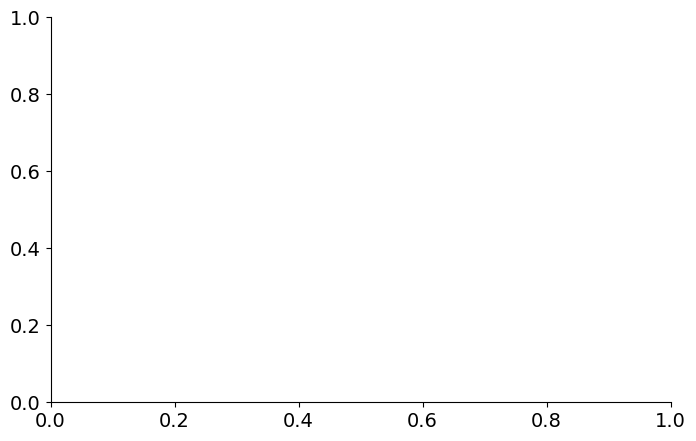

In [108]:
summ.plot_preferred_distance_bars(condition='binocular')

AttributeError: 'str' object has no attribute 'loc'

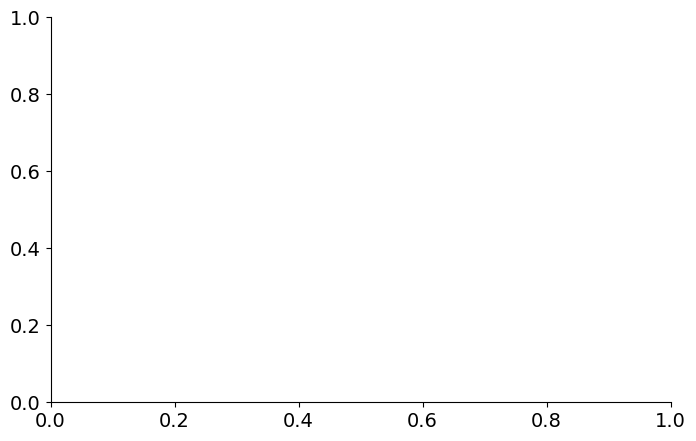

In [103]:
summ.plot_preferred_distance_bars()

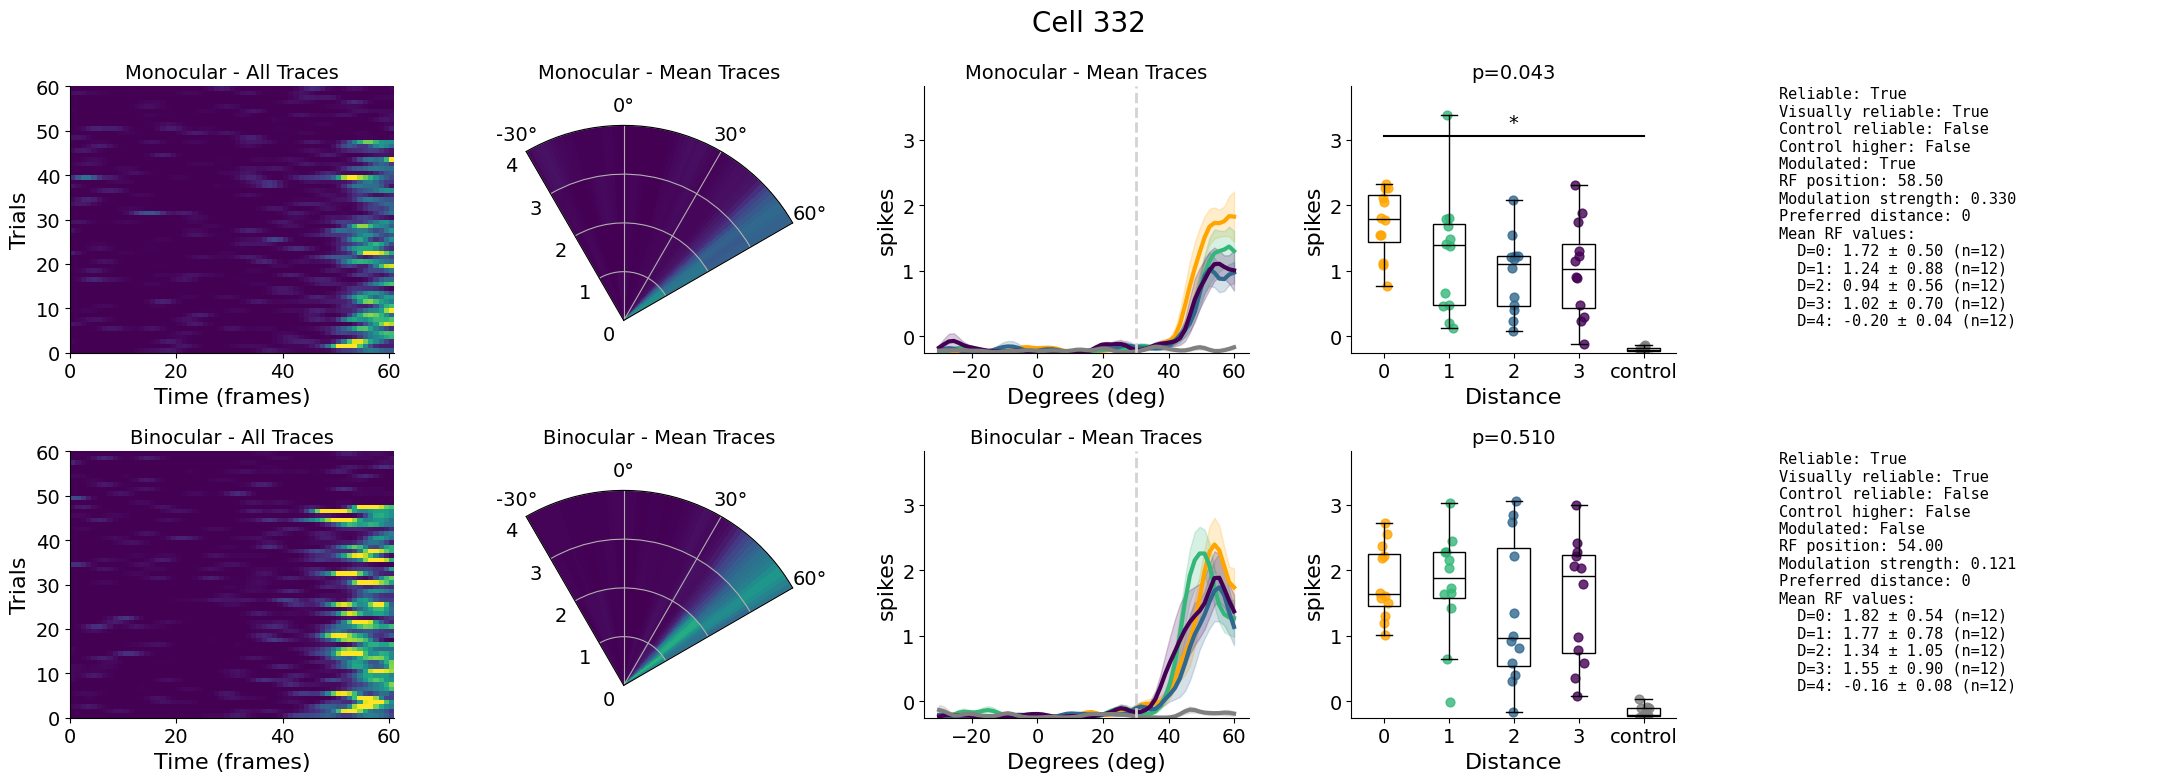

In [7]:
fig = summ.radial_plots.plot_all_traces_colormap_distances(cell=332)

In [43]:
summ.R.analyze_cell_modulation(cell=183, monocular=False)

(np.float32(0.016128017), np.int64(2), np.float32(0.70430964))

In [44]:
summ.radial_stats[summ.radial_stats['cell_id'] == ]

,cell_id,is_responsive,rf,ocular_dominance_index,monocular_modulated,monocular_modulated_p,monocular_strength,monocular_distance,monocular_rf,binocular_modulated,binocular_modulated_p,binocular_strength,binocular_distance,binocular_rf
296,310,True,[31.5],0.043152,False,0.197295,-0.008149,3,[36.0],False,0.118476,0.812236,3,[27.0]


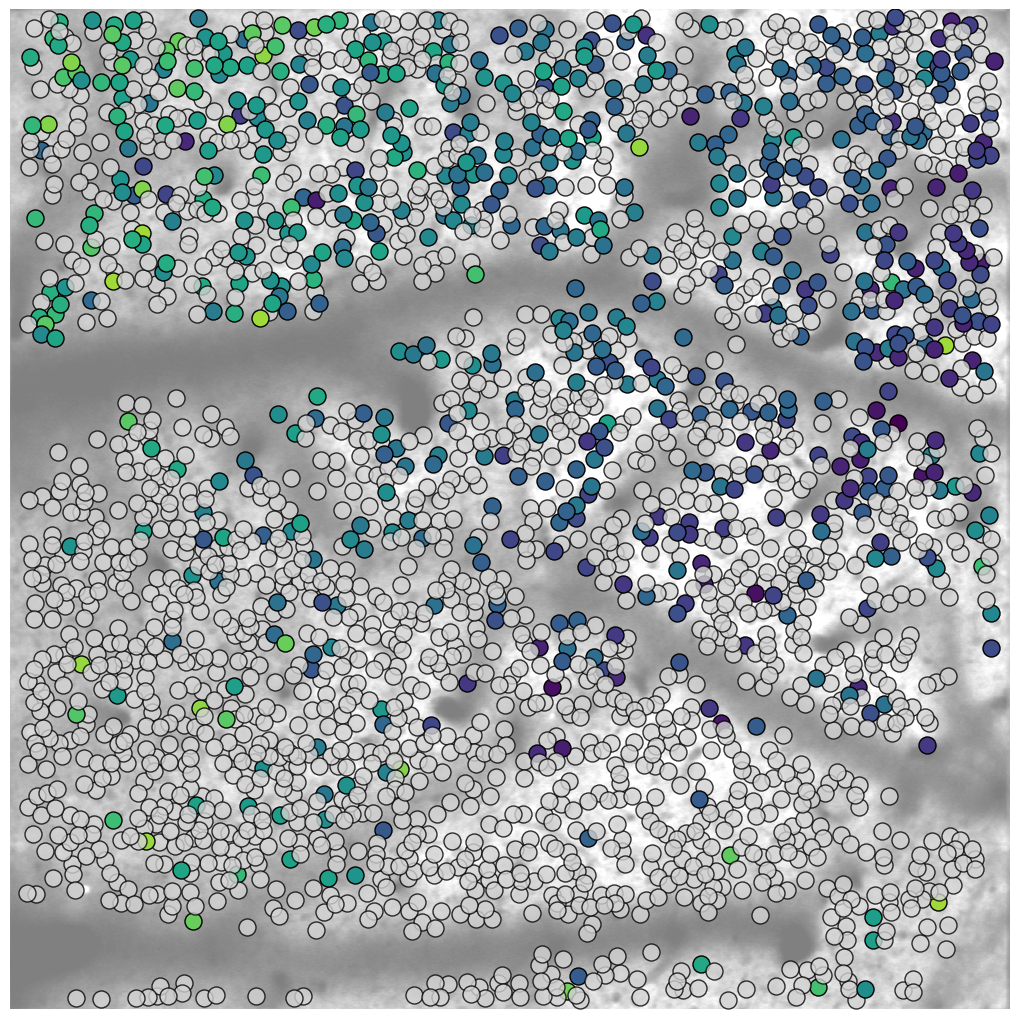

In [25]:
fig = summ.plot_reliable_cells_map()

AttributeError: 'str' object has no attribute 'empty'

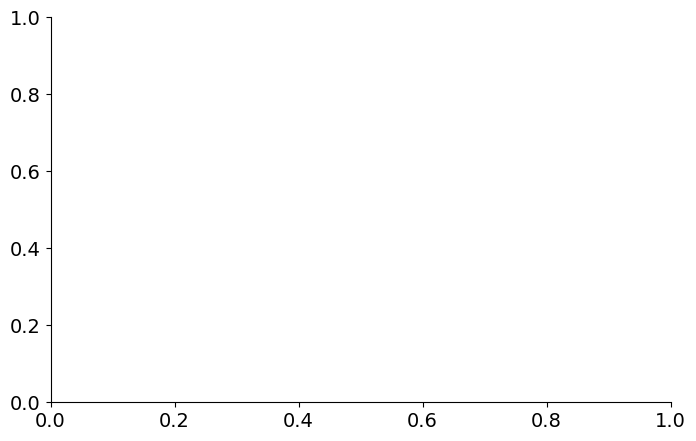

In [103]:
summ.plot_responsive_bars()

In [ ]:
stats_df.head()

,cell_id,is_responsive,rf,monocular_modulated,monocular_modulated_p,monocular_strength,monocular_distance,monocular_rf,binocular_modulated,binocular_modulated_p,binocular_strength,binocular_distance,binocular_rf
0,0,True,[-1.0169491525423737],False,0.609132,0.021775,1,[0.5084745762711833],False,0.192448,0.028509,1,[-2.5423728813559343]
1,1,False,[-2.5423728813559343],False,0.611610,0.124652,0,[-1.0169491525423737],False,0.998297,-0.098880,1,[-2.5423728813559343]
2,2,False,[53.89830508474576],False,0.963517,-0.623394,1,[52.37288135593219],False,0.969249,-0.710178,2,[55.42372881355932]
3,3,False,[8.135593220338983],False,0.884894,-0.649799,1,[9.66101694915254],False,0.446498,0.087630,2,[8.135593220338983]
4,4,False,[-20.847457627118644],False,0.203826,0.979104,1,[58.474576271186436],False,0.278779,0.414350,1,[-4.067796610169491]


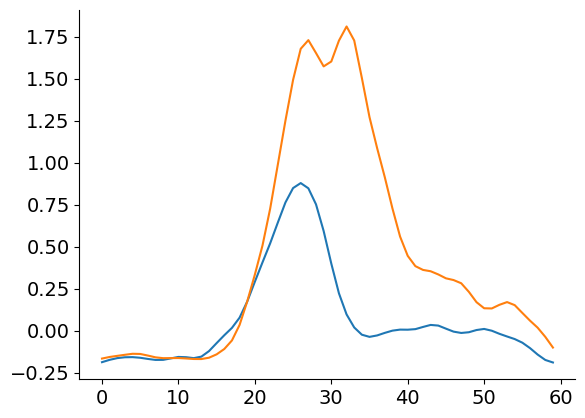

In [119]:
monocular_mean = D.get_all_traces(cell=2428, distance=None, monocular=True, mean_trace=True)[0]
plt.plot(monocular_mean)
binocular_mean = D.get_all_traces(cell=2428, distance=None, monocular=False, mean_trace=True)[0]
plt.plot(binocular_mean)

In [48]:
plots = RadialPlots(D)

In [82]:
summ = RadialSummaries(radial_class=D, radial_stats=stats_df, radial_plots=plots)

Total cells: 4057
Responsive cells: 998 (24.6%)
Monocular modulated cells: 28 (2.8%)
Binocular modulated cells: 99 (9.9%)
Both modulated cells: 7 (0.7%)
Non-modulated cells: 864 (86.6%)


In [84]:
fig = plt.figure(figsize=(8, 5))
        ax = fig.add_subplot(1, 1, 1, polar=True)

        # Plot preferred distance and angle for each condition
        pref_distances = []
        pref_angles = []
        for cell in self.modulated_cells[condition]:
            pref_distance = self.pullout_stat(cell_id=cell, condition=condition, stat_type='pref_distance')
            pref_angle = self.pullout_stat(cell_id=cell, condition=condition, stat_type='pref_angle')
            pref_distances.append(pref_distance)
            pref_angles.append(pref_angle)

        print(pref_distances)
        print(pref_angles)
        
        theta = np.radians(pref_angles)
        pref_distances = np.array(pref_distances)
        ax.scatter(theta, pref_distances, c=self.colors[condition], s=40, edgecolor='k', alpha=0.9, label=condition.capitalize())

        ax.set_theta_zero_location('N')
        ax.set_theta_direction(-1)
        ax.set_thetamin(-30)
        ax.set_thetamax(60)
        fig.suptitle('Modulation by Preferred Angle', fontsize=18, color='black', y=0.94)
        ax.set_title(self.session_name, fontsize=14, color='grey', pad=2)
        ax.set_ylabel('Preferred Distance')
        ax.legend()

        plt.tight_layout()

Plotting monocular cells
Creating directory: monocular
Plotting binocular cells
Creating directory: binocular
Plotting both cells
Creating directory: both
Plotting none cells
Creating directory: none


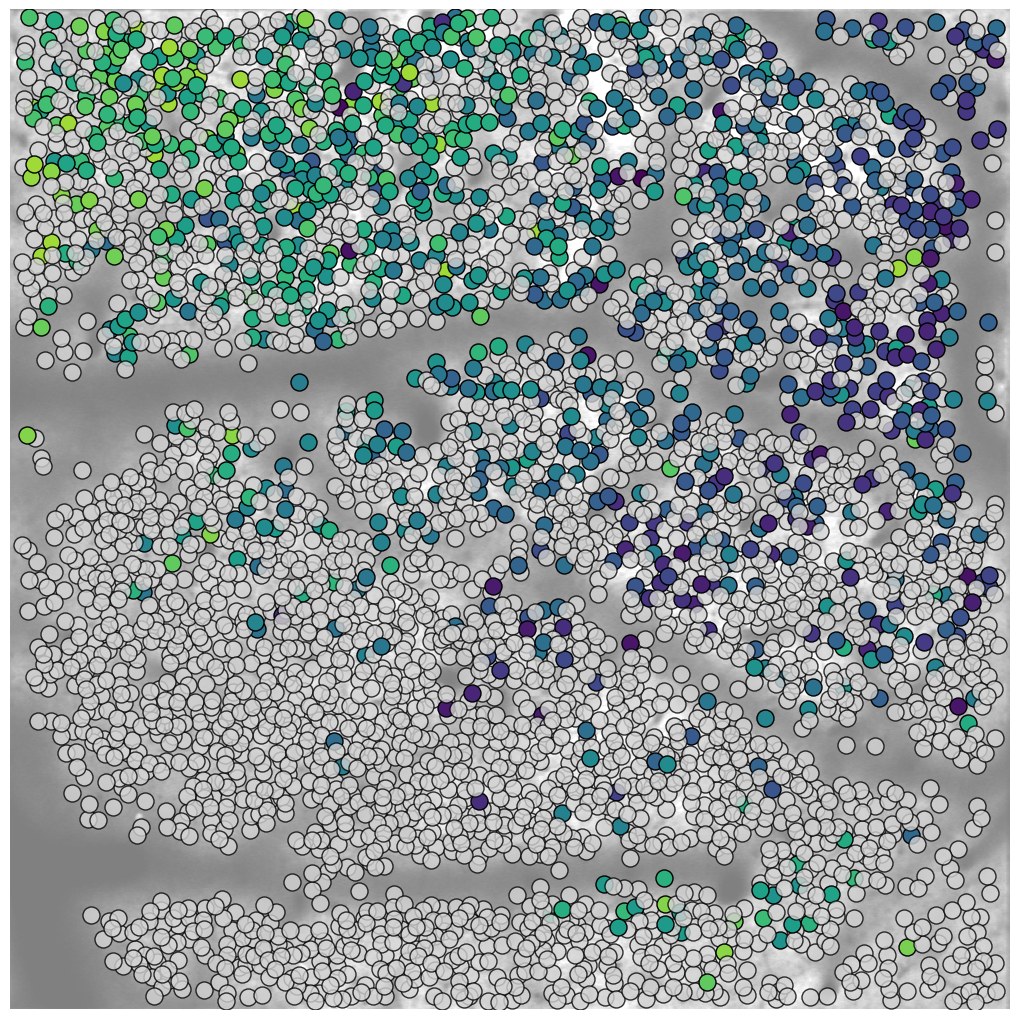

In [96]:
fig = summ.plot_reliable_cells_map()

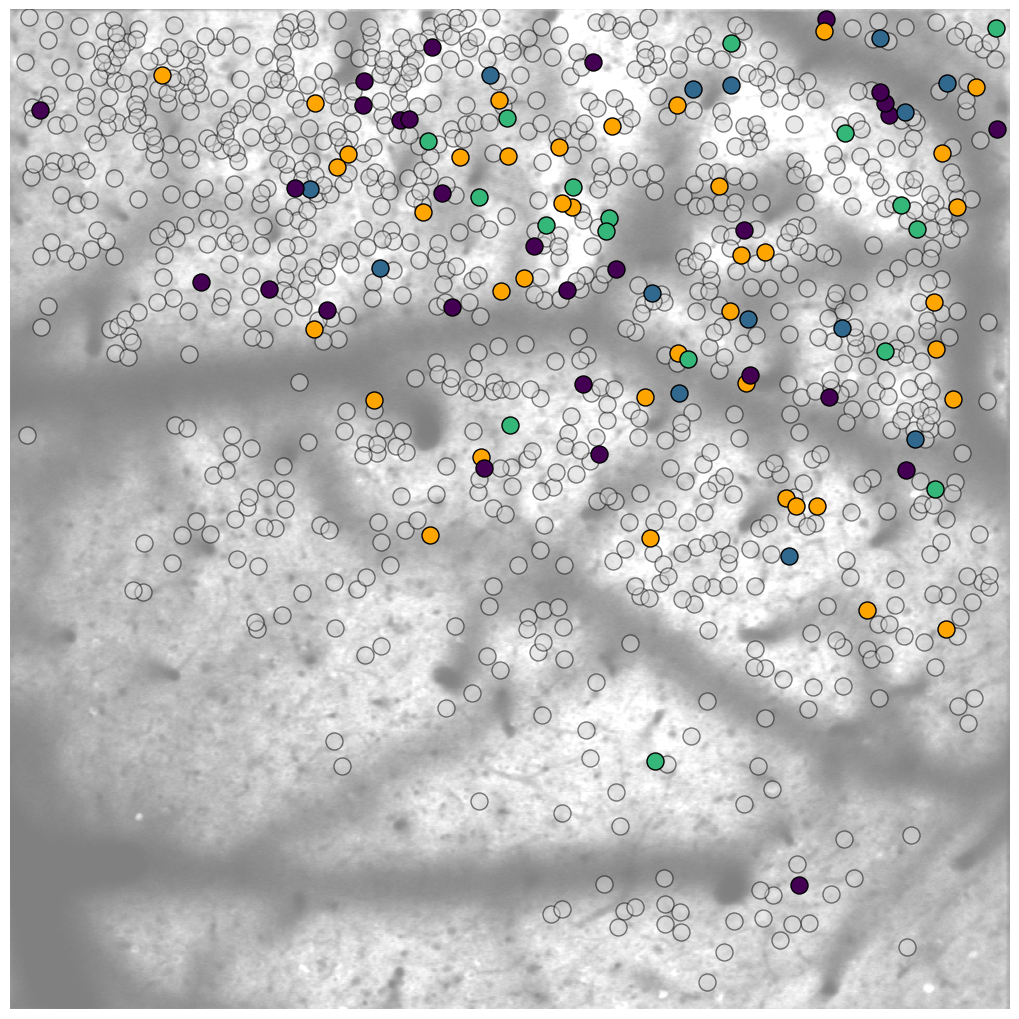

In [100]:
fig = summ.plot_modulated_cells_map()